# Epoch-Based Causality (State-Dependent Networks)

This notebook compares causal directionality and weights across defined behavioral epochs 
using the newly added timing metadata (e.g., `inarena_min`, `juvenile_first_sniff_min`).

**Goal**: Observe how causality dynamically restructures across: Baseline -> Shift -> Interaction -> Removal.

In [17]:
import sys
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to path
try:
    project_root = Path(__file__).resolve().parents[2]
except NameError:
    project_root = Path("../../").resolve()
    
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from monoamine_interactions.analysis.phase_1_causality import varlingam
from monoamine_interactions.notebooks.utils.photometry import motion_correct_biexponential

In [18]:
# 1. Load Data
pkl_path = project_root / "monoamine_interactions" / "data" / "sessions_jonathan_juvenile_intruder_dirty.pkl"
print(f"Loading {pkl_path}...")
with open(pkl_path, "rb") as f:
    sessions = pickle.load(f)
print(f"Loaded {len(sessions)} sessions.")

# Define epochs from metadata keys
EPOCHS = [
    ("Exploration", "inarena_min", "home_cage_min"),
    ("Anticipation", "home_cage_min", "juvenile_first_sniff_min"),
    ("Interaction", "juvenile_first_sniff_min", "juvenile_removed_min"),
    ("Recovery", "juvenile_removed_min", "homecage_removed_min")
]

# Configure LiNGAM
LAG = 5

Loading /home/fsp585/Desktop/FiberphotometryCode/monoamine_interactions/data/sessions_jonathan_juvenile_intruder_dirty.pkl...
Loaded 12 sessions.


> [!WARNING] TODO: Future Pipeline Upgrades
> **1. VARX-LiNGAM (Exogenous Regression):** Implement a pre-filtering step where kinematic variables (velocity, distance_to_intruder) from DLC are used as Exogenous Variables ($U$). Regress these out to isolate pure internal brain-to-brain communication.
>
> **2. Non-Linear Proxies:** Pass squared traces ($\Delta F/F^2$) alongside the raw traces into VARLiNGAM to test for non-linear multiplicative gating between regions.

In [19]:
# 2. Extract Data Per Epoch
epoch_results = {ep[0]: [] for ep in EPOCHS}

# Deduplicate sessions by photometry_csv_path
unique_sessions = []
seen_csvs = set()
for s in sessions:
    csv_path = s.metadata.get('photometry_csv_path')
    if csv_path and csv_path not in seen_csvs:
        seen_csvs.add(csv_path)
        unique_sessions.append(s)
sessions = unique_sessions
print(f"Post-deduplication: {len(sessions)} unique biological sessions.")

for s in tqdm(sessions, desc="Processing Sessions"):
    # Identify signals from signal_meta
    sm = s.metadata.get("signal_meta", {})
    region_map = {k: v.get("region") for k, v in sm.items() if v.get("region")}
    regions = list(region_map.values())
    
    if len(regions) < 2: continue
    if '470' not in s.photometry: continue
        
    df_470 = s.photometry['470']
    df_415 = s.photometry['415']
    ts_array = df_470['SystemTimestamp'].values
    ts_start = ts_array[0]
    
    # Process ISO corrected dff traces securely
    dff_dict = {}
    valid_regs = []
    global_mask = None
    
    for r in regions:
        try:
            col = next((k for k, v in region_map.items() if v == r))
            raw_470 = df_470[col].values
            raw_415 = df_415[col].values
            dff = motion_correct_biexponential(raw_470, raw_415)
            dff_dict[r] = dff
            valid_regs.append(r)
            
            mask = ~np.isnan(dff)
            if global_mask is None:
                global_mask = mask
            else:
                global_mask = global_mask & mask
        except Exception:
            pass

    if global_mask is None or not global_mask.any() or len(valid_regs) < 2:
        continue

    ep_ranges = {}
    tm = s.metadata.get("timing_meta", {})
    for ep_name, start_key, end_key in EPOCHS:
        t_start_min = tm.get(start_key)
        t_end_min = tm.get(end_key)
        
        if pd.isna(t_start_min) or pd.isna(t_end_min):
            continue
            
        # Add 3.0 second startle buffer to salient epochs (including recovery transients)
        buffer_sec = 3.0 if ep_name in ["Anticipation", "Interaction", "Recovery"] else 0.0
        target_ts_start = ts_start + (t_start_min * 60) + buffer_sec
        target_ts_end = ts_start + (t_end_min * 60)
        
        start_idx = np.abs(ts_array - target_ts_start).argmin()
        end_idx = np.abs(ts_array - target_ts_end).argmin()
        
        if (end_idx - start_idx) > 100:
            ep_ranges[ep_name] = (start_idx, end_idx)

    # Slice and run VARLiNGAM for each Epoch
    for ep_name in ep_ranges:
        start_idx, end_idx = ep_ranges[ep_name]
            
        # Create Dataframe specifically from the sliced valid frames
        ep_data = {}
        for r in valid_regs:
            sliced_trace = dff_dict[r][start_idx:end_idx]
            sliced_mask = global_mask[start_idx:end_idx]
            ep_data[r] = sliced_trace[sliced_mask]
            
        df_multi = pd.DataFrame(ep_data).dropna()
        if df_multi.empty: continue
        
        # --- CAUSAL STABILITY: ADAPTIVE BOOTSTRAPPING ---
        # For LONG phases (>10 min = ~12000 samples), bootstrap to represent full distribution.
        # For SHORT phases (Anticipation, Interaction), run once on full epoch to avoid sign-flip cancellation.
        n_bootstraps = 20
        block_len = 600     # 30 seconds of 20Hz data
        long_phase_threshold = 12000  # ~10 minutes
        
        if len(df_multi) >= long_phase_threshold:
            # Long phase: draw random continuous blocks
            boot_dfs = []
            for _ in range(n_bootstraps):
                rand_start = np.random.randint(0, len(df_multi) - block_len)
                boot_dfs.append(df_multi.iloc[rand_start:rand_start + block_len])
        else:
            # Short phase: single run on full epoch
            boot_dfs = [df_multi]
                
        adj_stack = []
        for b_df in boot_dfs:
            try:
                res = varlingam.run_varlingam(b_df, lags=LAG)
                adj_stack.append(res['adjacency_matrices'][0])
            except Exception:
                pass
                
        if not adj_stack: continue
        
        # Use median to aggregate (robust to outlier runs)
        adj = np.nanmedian(np.stack(adj_stack), axis=0)
            
        epoch_results[ep_name].append({
            "session": s.session_id,
            "animal": s.metadata.get("animal_id"),
            "regions": valid_regs,
            "adj_matrix": adj
        })

Post-deduplication: 10 unique biological sessions.


Processing Sessions: 100%|██████████| 10/10 [00:06<00:00,  1.65it/s]



--- Median Causal Weights by Phase ---


,epoch,Exploration_Early,Exploration_Late,Anticipation,Interaction,Recovery_Early,Recovery_Late
source,target,,,,,,
lNAc_5HT,rNAc_DA,0.0000,0.0000,-0.2819,-0.1784,-0.2748,0.0987
NAc_5HT,DRN_NE,0.1172,0.1694,0.0000,0.0000,0.0207,0.0000
rNAc_DA,lNAc_5HT,0.0000,0.0000,0.0615,0.0000,0.0000,-0.0331
DRN_NE,NAc_5HT,0.0000,0.0000,0.0000,0.0368,0.0000,0.0239
lNAc_DA,rNAc_5HT,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
rNAc_5HT,lNAc_DA,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


/home/fsp585/miniforge3/envs/kpms_gpu/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/fsp585/miniforge3/envs/kpms_gpu/lib/python3.10/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(aggregator, agg_var)
/home/fsp585/miniforge3/envs/kpms_gpu/lib/python3.10/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a futur

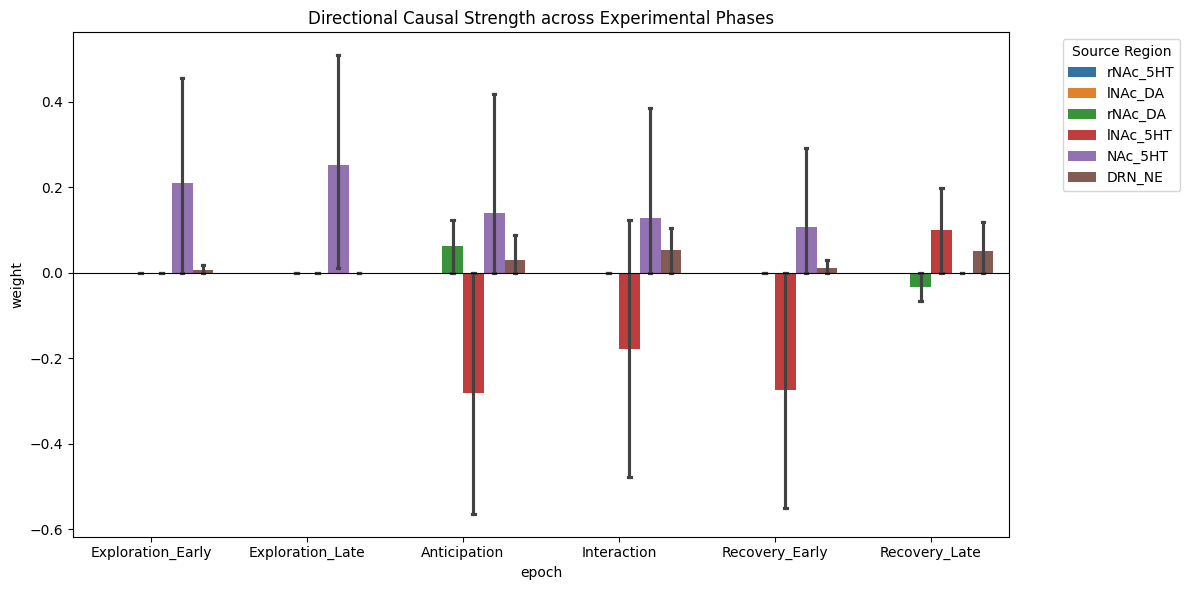

In [20]:
# 3. Aggregate, Summarize, and Plot
import seaborn as sns

edge_records = []
for ep_name, results in epoch_results.items():
    for res in results:
        regs = res["regions"]
        adj = res["adj_matrix"]
        for i, target in enumerate(regs):
            for j, source in enumerate(regs):
                if i == j: continue
                edge_records.append({
                    "epoch": ep_name,
                    "source": source,
                    "target": target,
                    "weight": adj[i, j]
                })

if not edge_records:
    print("No causal data found.")
else:
    df_edges = pd.DataFrame(edge_records)
    
    # Chronological epoch ordering
    chrono_order = [e[0] for e in EPOCHS if e[0] in df_edges["epoch"].unique()]

    # --- Summary Table ---
    summary_table = df_edges.groupby(["source", "target", "epoch"])["weight"].median().unstack("epoch")
    summary_table = summary_table[[c for c in chrono_order if c in summary_table.columns]]
    summary_table["max_abs"] = summary_table.abs().max(axis=1)
    summary_table = summary_table.sort_values("max_abs", ascending=False).drop(columns="max_abs")
    
    print("\n--- Median Causal Weights by Phase ---")
    try:
        from IPython.display import display
        display(summary_table.round(4))
    except ImportError:
        print(summary_table.round(4).to_string())

    # --- Bar Plot ---
    plt.figure(figsize=(12, 6))
    sns.barplot(data=df_edges, x="epoch", y="weight", hue="source", order=chrono_order, capsize=.1)
    plt.title("Directional Causal Strength across Experimental Phases")
    plt.axhline(0, color='black', linewidth=0.8)
    plt.legend(title="Source Region", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

    plt.show()